# 04 — Customer Segmentation

## Restaurant Customer Intelligence

This notebook develops a data-driven customer segmentation using unsupervised
machine learning.

The objective is to identify customer groups based on behavioral, economic,
and demographic characteristics, and compare the resulting clusters with the
rule-based segmentation proposed in the original project.

### Objectives

1. Prepare customer features for clustering.
2. Handle missing values within the modeling workflow.
3. Standardize numerical features to ensure comparable scale.
4. Evaluate alternative numbers of clusters.
5. Select a segmentation using quantitative metrics and business interpretability.
6. Profile and interpret the resulting customer segments.
7. Compare the data-driven segmentation with the original rule-based approach.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.cluster import KMeans
from sklearn.impute import SimpleImputer
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

In [2]:
DATA_PATH = Path("../data/processed/customers_features.csv")

df = pd.read_csv(DATA_PATH)

print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")

df.head()

Rows: 30,000
Columns: 16


,id_persona,edad,genero,ciudad_residencia,estrato_socioeconomico,frecuencia_visita,promedio_gasto_comida,ocio,consume_licor,preferencias_alimenticias,membresia_premium,tipo_de_pago_mas_usado,ingresos_mensuales,grupo_edad,premium_flag,spending_income_ratio
0,2550327378,31.00,Masculino,Miami,Alto,6.00,67.51,Sí,No,Vegetariano,Sí,Efectivo,6425,25-34,1,0.01
1,9446112038,40.00,Femenino,Denver,Medio,2.00,44.92,Sí,Sí,Mariscos,No,Efectivo,2374,35-44,0,0.02
2,3098363243,62.00,Femenino,Denver,Bajo,2.00,9.24,Sí,Sí,Vegetariano,No,Efectivo,1110,55-64,0,0.01
3,4013002847,41.00,Masculino,Boston,Alto,5.00,30.74,Sí,Sí,Carnes,Sí,Tarjeta,6931,35-44,1,0.00
4,7372911048,49.00,Femenino,San Diego,Bajo,0.00,0.00,No,No,Carnes,No,Tarjeta,1350,45-54,0,0.00


## 1. Segmentation feature set

The initial clustering configuration focuses on six numerical features:

- Age
- Visit frequency
- Average food spending
- Monthly income
- Premium membership
- Spending-to-income ratio

These variables capture demographic information, customer behavior, purchasing
power, membership status, and relative spending intensity.

Variables such as city, socioeconomic segment, food preference, and payment
method are initially excluded from cluster generation and retained for
subsequent cluster interpretation.

This separation prevents descriptive categorical variables from dominating
the initial segmentation and allows the customer-value structure to be
evaluated independently.

In [3]:
segmentation_features = [
    "edad",
    "frecuencia_visita",
    "promedio_gasto_comida",
    "ingresos_mensuales",
    "premium_flag",
    "spending_income_ratio"
]

X = df[segmentation_features].copy()

X.describe().T

,count,mean,std,min,25%,50%,75%,max
edad,"29,692.00",48.92,18.16,18.00,33.00,49.00,65.00,80.00
frecuencia_visita,"28,453.00",4.27,2.28,0.00,3.00,4.00,6.00,10.00
promedio_gasto_comida,"29,855.00",32.60,26.40,0.00,13.29,25.51,44.40,149.97
ingresos_mensuales,"30,000.00","5,389.76","4,538.49",800.00,"1,860.00","3,402.00","7,761.00","17,999.00"
premium_flag,"30,000.00",0.43,0.49,0.00,0.00,0.00,1.00,1.00
spending_income_ratio,"29,855.00",0.01,0.00,0.00,0.00,0.01,0.01,0.03


In [4]:
missing_summary = pd.DataFrame({
    "missing": X.isna().sum(),
    "missing_pct": (X.isna().mean() * 100).round(2)
})

missing_summary

,missing,missing_pct
edad,308,1.03
frecuencia_visita,1547,5.16
promedio_gasto_comida,145,0.48
ingresos_mensuales,0,0.00
premium_flag,0,0.00
spending_income_ratio,145,0.48


In [5]:
X.median()

edad                       49.00
frecuencia_visita           4.00
promedio_gasto_comida      25.51
ingresos_mensuales      3,402.00
premium_flag                0.00
spending_income_ratio       0.01
dtype: float64

In [6]:
frequency_missing_profile = (
    df.assign(
        frequency_missing=df["frecuencia_visita"].isna()
    )
    .groupby("frequency_missing")
    .agg(
        customers=("id_persona", "count"),
        avg_age=("edad", "mean"),
        avg_spending=("promedio_gasto_comida", "mean"),
        avg_income=("ingresos_mensuales", "mean"),
        premium_pct=("premium_flag", "mean")
    )
)

frequency_missing_profile["premium_pct"] *= 100

frequency_missing_profile.round(2)

,customers,avg_age,avg_spending,avg_income,premium_pct
frequency_missing,,,,,
False,28453,48.96,32.55,"5,392.69",42.88
True,1547,48.14,33.59,"5,335.80",41.69


In [7]:
missing_patterns = pd.DataFrame({
    "age_missing": df["edad"].isna(),
    "frequency_missing": df["frecuencia_visita"].isna(),
    "spending_missing": df["promedio_gasto_comida"].isna()
})

missing_patterns.value_counts().reset_index(name="customers")

,age_missing,frequency_missing,spending_missing,customers
0,False,False,False,28024
1,False,True,False,1524
2,True,False,False,294
3,False,False,True,134
4,True,True,False,13
5,False,True,True,10
6,True,False,True,1


### Missing-value assessment

Customers with missing visit frequency show a profile very similar to customers
with observed frequency:

- Average age: 48.14 vs. 48.96
- Average food spending: 33.59 vs. 32.55
- Average monthly income: 5,335.80 vs. 5,392.69
- Premium membership: 41.69% vs. 42.88%

Most missing values also occur independently. Of the 30,000 customers, 28,024
have complete segmentation features, while 1,524 records contain only missing
visit frequency.

There is no evidence that missing visit frequency represents a distinct customer
segment.

**Decision:** median imputation will be evaluated as a practical strategy for
retaining the full customer base. Clustering results will also be compared with
a complete-case baseline to verify that imputation does not materially alter
the segmentation structure.

In [8]:
X_complete = X.dropna().copy()

print(f"Complete-case customers: {len(X_complete):,}")
print(f"Share of total: {len(X_complete) / len(X) * 100:.2f}%")

Complete-case customers: 28,024
Share of total: 93.41%


In [9]:
imputer = SimpleImputer(strategy="median")

X_imputed = pd.DataFrame(
    imputer.fit_transform(X),
    columns=X.columns,
    index=X.index
)

imputation_values = pd.Series(
    imputer.statistics_,
    index=X.columns,
    name="median_imputation"
)

imputation_values

edad                       49.00
frecuencia_visita           4.00
promedio_gasto_comida      25.51
ingresos_mensuales      3,402.00
premium_flag                0.00
spending_income_ratio       0.01
Name: median_imputation, dtype: float64

In [10]:
print("Missing values after imputation:")
print(X_imputed.isna().sum())

assert X_imputed.isna().sum().sum() == 0
assert len(X_imputed) == 30_000

print("\nImputation validation passed.")

Missing values after imputation:
edad                     0
frecuencia_visita        0
promedio_gasto_comida    0
ingresos_mensuales       0
premium_flag             0
spending_income_ratio    0
dtype: int64

Imputation validation passed.


## 2. Feature scaling

K-Means clustering is distance-based and therefore sensitive to differences in
feature scale.

The segmentation variables operate on substantially different ranges. Monthly
income, for example, is measured in thousands of dollars, while Premium
membership is binary.

StandardScaler is therefore applied so that each feature has approximately zero
mean and unit variance before clustering.

Scaling parameters are fitted separately for the complete-case and imputed
datasets.

In [11]:
scaler_complete = StandardScaler()
scaler_imputed = StandardScaler()

X_complete_scaled = scaler_complete.fit_transform(X_complete)
X_imputed_scaled = scaler_imputed.fit_transform(X_imputed)

print("Complete-case scaled shape:", X_complete_scaled.shape)
print("Imputed scaled shape:", X_imputed_scaled.shape)

Complete-case scaled shape: (28024, 6)
Imputed scaled shape: (30000, 6)


In [12]:
scaled_check = pd.DataFrame(
    X_imputed_scaled,
    columns=segmentation_features
).agg(["mean", "std"])

scaled_check.round(3)

,edad,frecuencia_visita,promedio_gasto_comida,ingresos_mensuales,premium_flag,spending_income_ratio
mean,-0.00,-0.00,-0.00,0.00,0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00


## 3. Selecting the number of clusters

The original project proposed four customer segments based on manually defined
business rules. In this analysis, the number of clusters is not predetermined.

K-Means models are evaluated across multiple values of K using:

- Inertia (within-cluster sum of squares)
- Silhouette score
- Cluster size distribution
- Business interpretability

Both the complete-case and imputed datasets are evaluated to determine whether
the treatment of missing values materially affects the segmentation structure.

In [13]:
def evaluate_kmeans(X_scaled, k_range=range(2, 9)):
    results = []

    for k in k_range:
        model = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=10
        )

        labels = model.fit_predict(X_scaled)

        results.append({
            "k": k,
            "inertia": model.inertia_,
            "silhouette": silhouette_score(
                X_scaled,
                labels,
                sample_size=min(10000, len(X_scaled)),
                random_state=42
            )
        })

    return pd.DataFrame(results)

In [14]:
complete_results = evaluate_kmeans(X_complete_scaled)
imputed_results = evaluate_kmeans(X_imputed_scaled)

complete_results

,k,inertia,silhouette
0,2,"106,444.67",0.34
1,3,"90,189.21",0.28
2,4,"76,368.16",0.24
3,5,"67,971.95",0.24
4,6,"61,079.63",0.24
5,7,"55,697.54",0.25
6,8,"50,470.32",0.26


In [15]:
imputed_results

,k,inertia,silhouette
0,2,"114,666.50",0.34
1,3,"97,298.02",0.28
2,4,"82,620.22",0.24
3,5,"73,595.82",0.24
4,6,"66,221.89",0.24
5,7,"60,608.23",0.24
6,8,"54,904.83",0.26


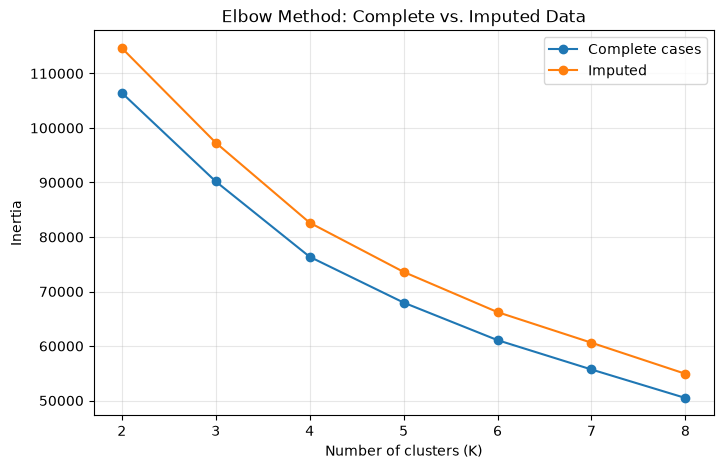

In [16]:
plt.figure(figsize=(8, 5))

plt.plot(
    complete_results["k"],
    complete_results["inertia"],
    marker="o",
    label="Complete cases"
)

plt.plot(
    imputed_results["k"],
    imputed_results["inertia"],
    marker="o",
    label="Imputed"
)

plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method: Complete vs. Imputed Data")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

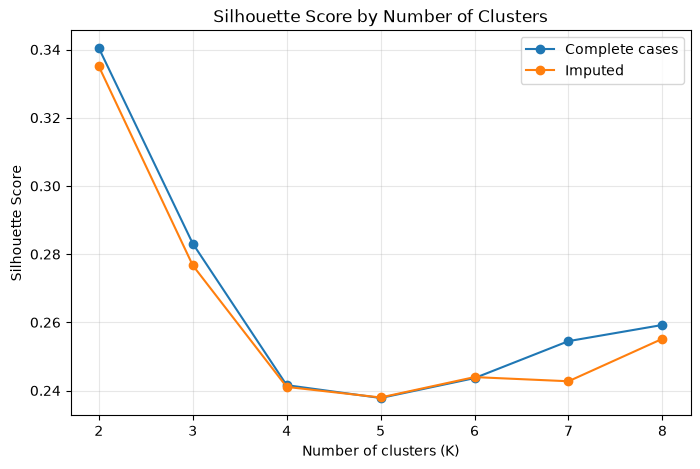

In [17]:
plt.figure(figsize=(8, 5))

plt.plot(
    complete_results["k"],
    complete_results["silhouette"],
    marker="o",
    label="Complete cases"
)

plt.plot(
    imputed_results["k"],
    imputed_results["silhouette"],
    marker="o",
    label="Imputed"
)

plt.xlabel("Number of clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score by Number of Clusters")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

### Initial cluster-count evaluation

The complete-case and median-imputed datasets produce highly similar inertia
and silhouette curves, indicating that median imputation does not materially
alter the underlying clustering structure.

The highest silhouette score occurs at K=2 (approximately 0.34), suggesting a
strong broad division within the customer base. However, this solution may be
too coarse for actionable customer segmentation.

The inertia curve shows substantial improvement through approximately K=4–5,
followed by progressively smaller reductions.

Silhouette scores decrease through K=4–5 and then partially recover for higher
values of K.

**Decision:** the final number of clusters will not be selected from a single
metric. Candidate solutions will be compared based on cluster size, customer
profiles, and business interpretability.

The imputed dataset will be used for subsequent analysis because it retains all
30,000 customers while preserving a clustering structure very similar to the
complete-case dataset.

In [18]:
candidate_k = [2, 3, 4, 6, 8]

cluster_size_results = []

for k in candidate_k:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_imputed_scaled)

    counts = pd.Series(labels).value_counts().sort_index()

    for cluster, count in counts.items():
        cluster_size_results.append({
            "k": k,
            "cluster": cluster,
            "customers": count,
            "pct_customers": count / len(X_imputed) * 100
        })

cluster_sizes = pd.DataFrame(cluster_size_results)

cluster_sizes.round(2)

,k,cluster,customers,pct_customers
0,2,0,12306,41.02
1,2,1,17694,58.98
2,3,0,5126,17.09
3,3,1,16873,56.24
4,3,2,8001,26.67
5,4,0,7957,26.52
6,4,1,7084,23.61
7,4,2,10135,33.78
8,4,3,4824,16.08
9,6,0,2736,9.12


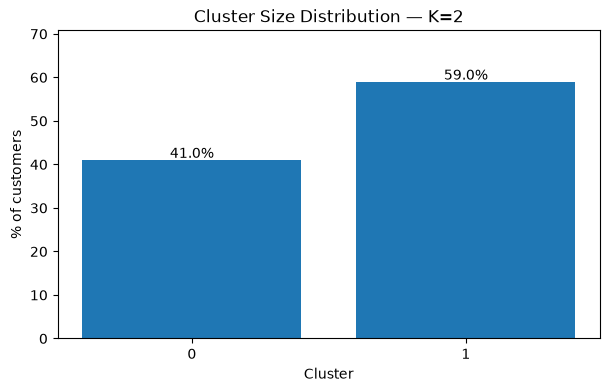

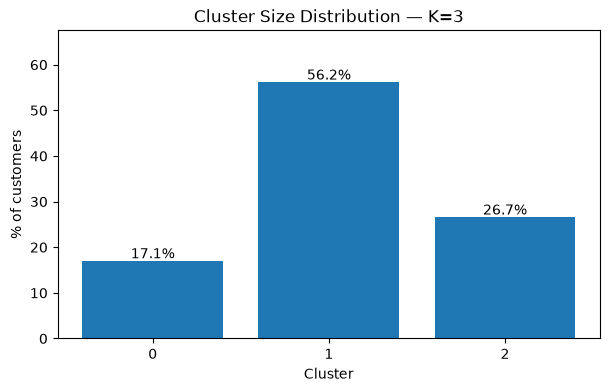

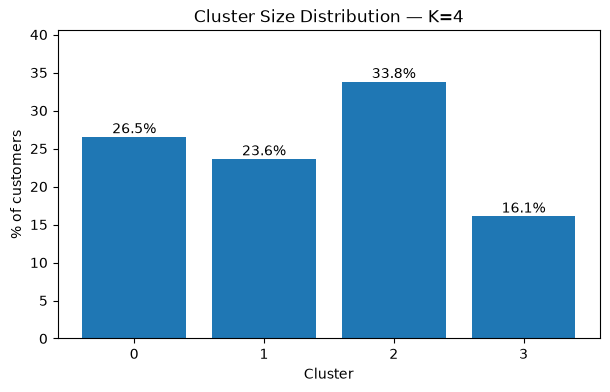

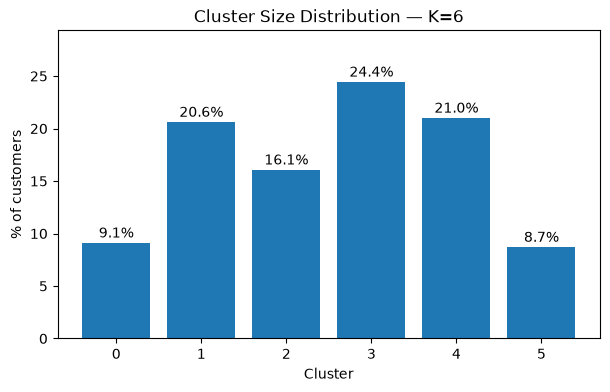

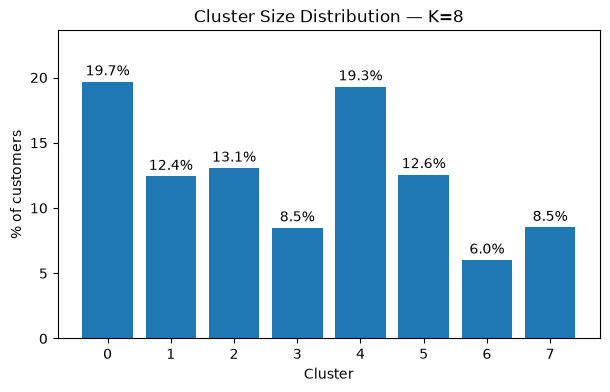

In [19]:
for k in candidate_k:
    subset = cluster_sizes[cluster_sizes["k"] == k]

    plt.figure(figsize=(7, 4))

    plt.bar(
        subset["cluster"].astype(str),
        subset["pct_customers"]
    )

    plt.xlabel("Cluster")
    plt.ylabel("% of customers")
    plt.title(f"Cluster Size Distribution — K={k}")
    plt.ylim(0, subset["pct_customers"].max() * 1.2)

    for i, value in enumerate(subset["pct_customers"]):
        plt.text(
            i,
            value + 0.5,
            f"{value:.1f}%",
            ha="center"
        )

    plt.show()

## 4. Candidate cluster profiling

Cluster quality cannot be evaluated only through statistical metrics or cluster
size.

Each candidate solution is profiled using the original customer variables to
determine whether the resulting groups represent distinct and commercially
meaningful customer behaviors.

The analysis compares K=2, K=3, K=4, K=6, and K=8.

In [20]:
def profile_clusters(k):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_imputed_scaled)

    temp = df.copy()
    temp["cluster"] = labels

    profile = (
        temp.groupby("cluster")
        .agg(
            customers=("id_persona", "count"),
            avg_age=("edad", "mean"),
            avg_frequency=("frecuencia_visita", "mean"),
            avg_spending=("promedio_gasto_comida", "mean"),
            avg_income=("ingresos_mensuales", "mean"),
            premium_pct=("premium_flag", "mean"),
            avg_spending_income_ratio=("spending_income_ratio", "mean")
        )
    )

    profile["pct_customers"] = (
        profile["customers"] / len(temp) * 100
    )

    profile["premium_pct"] *= 100

    return profile.round(2)

In [21]:
profile_k2 = profile_clusters(2)
profile_k3 = profile_clusters(3)
profile_k4 = profile_clusters(4)
profile_k6 = profile_clusters(6)
profile_k8 = profile_clusters(8)

In [22]:
profile_k2

,customers,avg_age,avg_frequency,avg_spending,avg_income,premium_pct,avg_spending_income_ratio,pct_customers
cluster,,,,,,,,
0,12306,48.58,6.12,49.98,"9,477.15",95.68,0.01,41.02
1,17694,49.15,2.98,20.51,"2,547.02",6.05,0.01,58.98


In [23]:
profile_k4

,customers,avg_age,avg_frequency,avg_spending,avg_income,premium_pct,avg_spending_income_ratio,pct_customers
cluster,,,,,,,,
0,7957,48.58,4.92,34.56,"6,337.54",98.04,0.01,26.52
1,7084,48.77,3.39,32.31,"2,482.08",6.37,0.01,23.61
2,10135,49.38,2.74,13.37,"2,685.60",0.08,0.01,33.78
3,4824,48.71,7.65,69.97,"13,777.63",95.05,0.01,16.08


### K=2 vs. K=4: business interpretability

The two-cluster solution produces the strongest silhouette score but primarily
separates the customer base into broad high-value and lower-value groups.

The four-cluster solution reveals additional commercially meaningful structure.

In particular:

- Cluster 3 represents a high-value segment with the highest visit frequency,
  spending, income, and very high Premium penetration.
- Cluster 0 also shows very high Premium penetration but substantially lower
  spending, income, and frequency than Cluster 3.
- Cluster 1 contains mostly non-Premium customers with moderate spending,
  suggesting potential membership-conversion opportunities.
- Cluster 2 represents the largest group and shows lower spending and visit
  frequency with almost no Premium membership.

The K=4 solution therefore separates customer profiles that are merged together
in the statistically stronger but commercially broader K=2 solution.

**Preliminary conclusion:** K=4 provides greater business interpretability, but
higher-K solutions will be evaluated before selecting the final segmentation.

In [24]:
print("K = 3")
display(profile_k3)

print("\nK = 6")
display(profile_k6)

print("\nK = 8")
display(profile_k8)

K = 3


,customers,avg_age,avg_frequency,avg_spending,avg_income,premium_pct,avg_spending_income_ratio,pct_customers
cluster,,,,,,,,
0,5126,48.75,7.59,67.43,"13,703.17",94.83,0.01,17.09
1,16873,49.12,3.01,20.74,"2,636.31",0.02,0.01,56.24
2,8001,48.59,4.78,35.25,"5,870.24",99.75,0.01,26.67



K = 6


,customers,avg_age,avg_frequency,avg_spending,avg_income,premium_pct,avg_spending_income_ratio,pct_customers
cluster,,,,,,,,
0,2736,48.37,7.57,36.49,"13,955.02",95.29,0.00,9.12
1,6187,65.53,2.75,15.18,"2,634.79",0.63,0.01,20.62
2,4824,49.77,3.42,34.83,"2,383.18",8.46,0.02,16.08
3,7335,48.63,4.83,35.52,"5,906.76",99.25,0.01,24.45
4,6305,32.49,2.98,16.87,"2,809.36",0.41,0.01,21.02
5,2613,48.96,7.46,94.96,"13,270.09",95.10,0.01,8.71



K = 8


,customers,avg_age,avg_frequency,avg_spending,avg_income,premium_pct,avg_spending_income_ratio,pct_customers
cluster,,,,,,,,
0,5901,32.67,3.43,19.95,"3,059.29",0.00,0.01,19.67
1,3728,47.65,3.29,34.54,"2,181.12",8.26,0.02,12.43
2,3918,33.15,4.84,34.76,"6,036.23",99.92,0.01,13.06
3,2543,48.79,7.50,95.59,"13,355.90",95.12,0.01,8.48
4,5786,66.17,3.35,20.33,"2,941.93",0.00,0.01,19.29
5,3767,64.91,4.80,36.70,"5,924.94",99.97,0.01,12.56
6,1803,50.13,0.30,1.36,"1,321.36",0.28,0.00,6.01
7,2554,48.55,7.69,36.46,"14,162.46",95.22,0.00,8.51


In [25]:
def add_ratio_pct(profile):
    result = profile.copy()
    result["spending_income_pct"] = (
        result["avg_spending_income_ratio"] * 100
    ).round(3)

    return result.drop(columns="avg_spending_income_ratio")

profile_k3_display = add_ratio_pct(profile_k3)
profile_k4_display = add_ratio_pct(profile_k4)
profile_k6_display = add_ratio_pct(profile_k6)
profile_k8_display = add_ratio_pct(profile_k8)

profile_k4_display

,customers,avg_age,avg_frequency,avg_spending,avg_income,premium_pct,pct_customers,spending_income_pct
cluster,,,,,,,,
0,7957,48.58,4.92,34.56,"6,337.54",98.04,26.52,1.00
1,7084,48.77,3.39,32.31,"2,482.08",6.37,23.61,1.00
2,10135,49.38,2.74,13.37,"2,685.60",0.08,33.78,1.00
3,4824,48.71,7.65,69.97,"13,777.63",95.05,16.08,1.00


In [26]:
display(profile_k3)
display(profile_k6)

,customers,avg_age,avg_frequency,avg_spending,avg_income,premium_pct,avg_spending_income_ratio,pct_customers
cluster,,,,,,,,
0,5126,48.75,7.59,67.43,"13,703.17",94.83,0.01,17.09
1,16873,49.12,3.01,20.74,"2,636.31",0.02,0.01,56.24
2,8001,48.59,4.78,35.25,"5,870.24",99.75,0.01,26.67


,customers,avg_age,avg_frequency,avg_spending,avg_income,premium_pct,avg_spending_income_ratio,pct_customers
cluster,,,,,,,,
0,2736,48.37,7.57,36.49,"13,955.02",95.29,0.00,9.12
1,6187,65.53,2.75,15.18,"2,634.79",0.63,0.01,20.62
2,4824,49.77,3.42,34.83,"2,383.18",8.46,0.02,16.08
3,7335,48.63,4.83,35.52,"5,906.76",99.25,0.01,24.45
4,6305,32.49,2.98,16.87,"2,809.36",0.41,0.01,21.02
5,2613,48.96,7.46,94.96,"13,270.09",95.10,0.01,8.71


## Final Cluster Selection

Several K-Means solutions were evaluated using both statistical performance
and business interpretability.

K=2 achieved the highest silhouette score (~0.34), indicating the strongest
statistical separation. However, it primarily divided customers into broad
high-value and lower-value groups, limiting its usefulness for targeted
business strategies.

K=3 provided a simple low-, medium-, and high-value structure, but still
offered limited behavioral differentiation.

Higher-dimensional solutions (K=6 and K=8) introduced additional customer
profiles, but several of these clusters were primarily separated by age rather
than meaningful differences in purchasing behavior. This increased complexity
without a proportional improvement in business actionability.

K=4 was therefore selected as the final segmentation because it provides the
best balance between statistical validity, interpretability, segment size, and
commercial usefulness.

The four segments reveal distinct customer profiles related to spending,
visit frequency, income, and Premium membership, enabling differentiated
retention, conversion, activation, and high-value customer strategies.

**Final model: K-Means with K=4.**

In [29]:
FINAL_K = 4

final_kmeans = KMeans(
    n_clusters=FINAL_K,
    random_state=42,
    n_init=20
)

df_segmented = df.copy()

df_segmented["cluster"] = final_kmeans.fit_predict(X_imputed_scaled)

df_segmented["cluster"].value_counts().sort_index()

cluster
0     7945
1    10077
2     4842
3     7136
Name: count, dtype: int64

In [28]:
[name for name, obj in globals().items() if isinstance(obj, pd.DataFrame)]

['df',
 'X',
 'missing_summary',
 'frequency_missing_profile',
 'missing_patterns',
 'X_complete',
 'X_imputed',
 'scaled_check',
 'complete_results',
 'imputed_results',
 'cluster_sizes',
 'subset',
 'profile_k2',
 'profile_k3',
 'profile_k4',
 'profile_k6',
 'profile_k8',
 'profile_k3_display',
 'profile_k4_display',
 'profile_k6_display',
 'profile_k8_display']

In [30]:
final_profile = (
    df_segmented
    .groupby("cluster")
    .agg(
        customers=("id_persona", "count"),
        avg_age=("edad", "mean"),
        avg_frequency=("frecuencia_visita", "mean"),
        avg_spending=("promedio_gasto_comida", "mean"),
        avg_income=("ingresos_mensuales", "mean"),
        premium_pct=("premium_flag", lambda x: x.mean() * 100),
        avg_spending_income_ratio=("spending_income_ratio", "mean")
    )
)

final_profile["pct_customers"] = (
    final_profile["customers"] / len(df_segmented) * 100
)

final_profile.round(2)

,customers,avg_age,avg_frequency,avg_spending,avg_income,premium_pct,avg_spending_income_ratio,pct_customers
cluster,,,,,,,,
0,7945,48.55,4.92,34.58,"6,317.99",98.07,0.01,26.48
1,10077,49.15,2.74,13.30,"2,685.20",0.08,0.01,33.59
2,4842,48.71,7.65,69.80,"13,775.00",95.06,0.01,16.14
3,7136,49.12,3.39,32.25,"2,485.84",6.19,0.01,23.79


In [31]:
food_preferences = pd.crosstab(
    df_segmented["cluster"],
    df_segmented["preferencias_alimenticias"],
    normalize="index"
) * 100

food_preferences.round(1)

preferencias_alimenticias,Carnes,Mariscos,Otro,Pescado,Vegano,Vegetariano
cluster,,,,,,
0,26.50,18.70,9.20,10.50,11.30,23.80
1,29.10,17.30,9.70,10.60,11.20,22.20
2,26.60,19.10,8.70,9.90,11.60,24.10
3,27.70,18.50,8.90,10.50,11.80,22.50


In [32]:
overall_food = (
    df_segmented["preferencias_alimenticias"]
    .value_counts(normalize=True) * 100
)

food_affinity = food_preferences.div(overall_food, axis=1) * 100

food_affinity.round(1)

preferencias_alimenticias,Carnes,Mariscos,Otro,Pescado,Vegano,Vegetariano
cluster,,,,,,
0,95.60,102.40,99.70,100.90,98.90,103.60
1,105.20,94.90,105.00,101.20,97.60,96.40
2,96.10,104.90,94.40,94.70,101.50,104.70
3,100.10,101.30,97.00,100.90,103.50,97.90


In [33]:
city_distribution = pd.crosstab(
    df_segmented["cluster"],
    df_segmented["ciudad_residencia"],
    normalize="index"
) * 100

city_distribution.round(1)

ciudad_residencia,Boston,Chicago,Dallas,Denver,Houston,Miami,NYC,Phoenix,San Diego,Seattle
cluster,,,,,,,,,,
0,8.70,18.50,8.40,8.70,6.50,12.40,12.90,4.80,11.50,7.60
1,9.80,25.60,10.30,8.80,7.90,6.70,12.20,4.10,8.90,5.70
2,9.60,16.30,6.80,7.50,5.90,14.90,13.70,4.90,12.40,8.20
3,5.60,7.70,8.00,8.20,8.70,11.30,26.00,6.80,9.20,8.60


In [34]:
overall_city = (
    df_segmented["ciudad_residencia"]
    .value_counts(normalize=True) * 100
)

city_affinity = city_distribution.div(overall_city, axis=1) * 100

city_affinity.round(1)

ciudad_residencia,Boston,Chicago,Dallas,Denver,Houston,Miami,NYC,Phoenix,San Diego,Seattle
cluster,,,,,,,,,,
0,103.00,103.30,96.50,103.00,87.70,116.60,81.20,95.00,112.60,104.10
1,115.80,142.50,118.60,104.90,107.00,63.00,76.80,80.60,87.00,78.30
2,112.90,90.70,77.90,88.70,79.80,140.60,85.90,96.40,121.10,112.30
3,65.50,42.60,92.60,97.50,117.50,106.20,163.30,135.50,90.00,117.80


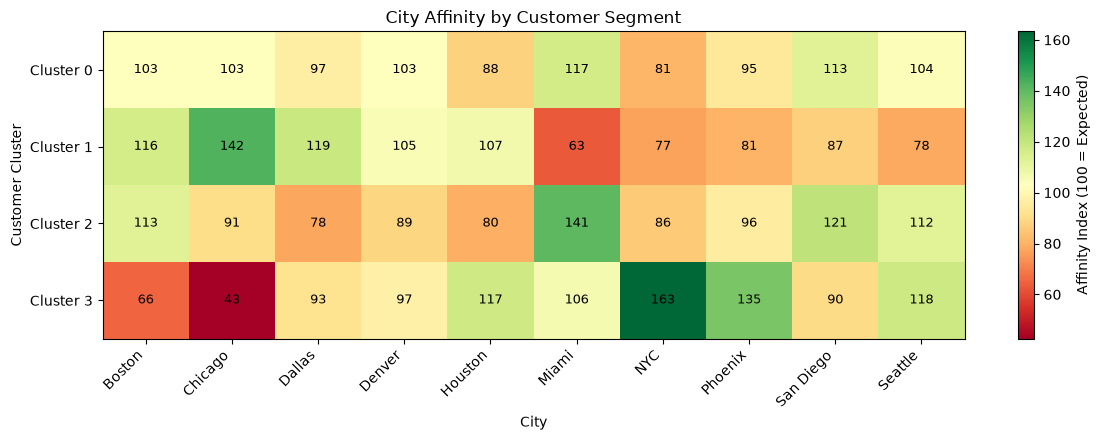

In [35]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 4.5))

im = ax.imshow(city_affinity, aspect="auto", cmap="RdYlGn")

ax.set_xticks(range(len(city_affinity.columns)))
ax.set_xticklabels(city_affinity.columns, rotation=45, ha="right")

ax.set_yticks(range(len(city_affinity.index)))
ax.set_yticklabels([f"Cluster {i}" for i in city_affinity.index])

for i in range(len(city_affinity.index)):
    for j in range(len(city_affinity.columns)):
        value = city_affinity.iloc[i, j]
        ax.text(
            j, i,
            f"{value:.0f}",
            ha="center",
            va="center",
            fontsize=9
        )

ax.set_title("City Affinity by Customer Segment")
ax.set_xlabel("City")
ax.set_ylabel("Customer Cluster")

cbar = plt.colorbar(im, ax=ax)
cbar.set_label("Affinity Index (100 = Expected)")

plt.tight_layout()
plt.show()

In [36]:
payment_distribution = pd.crosstab(
    df_segmented["cluster"],
    df_segmented["tipo_de_pago_mas_usado"],
    normalize="index"
) * 100

payment_distribution.round(1)

tipo_de_pago_mas_usado,App,Criptomoneda,Efectivo,Tarjeta
cluster,,,,
0,25.60,1.70,40.00,32.80
1,26.10,2.00,39.00,32.90
2,24.40,1.70,39.70,34.20
3,25.70,1.90,39.00,33.30


In [37]:
socioeconomic_distribution = pd.crosstab(
    df_segmented["cluster"],
    df_segmented["estrato_socioeconomico"],
    normalize="index"
) * 100

socioeconomic_distribution.round(1)

estrato_socioeconomico,Alto,Bajo,Medio,Muy Alto
cluster,,,,
0,78.80,0.20,12.50,8.50
1,16.30,43.10,40.40,0.10
2,1.20,0.00,0.00,98.80
3,15.00,25.20,59.70,0.00


In [38]:
segment_names = {
    0: "Established Premium",
    1: "Low Engagement",
    2: "High-Value Loyalists",
    3: "Conversion Potential"
}

df_segmented["segment"] = df_segmented["cluster"].map(segment_names)

df_segmented[
    ["id_persona", "cluster", "segment"]
].head(10)

,id_persona,cluster,segment
0,2550327378,0,Established Premium
1,9446112038,3,Conversion Potential
2,3098363243,1,Low Engagement
3,4013002847,0,Established Premium
4,7372911048,1,Low Engagement
5,1291749568,0,Established Premium
6,3592027247,2,High-Value Loyalists
7,8373803828,2,High-Value Loyalists
8,7395628831,1,Low Engagement
9,5394273061,1,Low Engagement


## Final Customer Segments

The final K-Means model identified four commercially meaningful customer
segments.

### 1. Established Premium — 26.5%

Customers in this segment show strong engagement and very high Premium
membership adoption (98%). They visit relatively frequently and have
above-average income and spending levels.

**Business objective:** retention and loyalty.

Potential actions include exclusive benefits, loyalty rewards, personalized
offers, and early access to new experiences.

---

### 2. Low Engagement — 33.6%

This is the largest customer segment. Customers show relatively low visit
frequency and the lowest average spending, with almost no Premium membership.

The segment is especially overrepresented in Chicago, Dallas, and Boston.

**Business objective:** activation and frequency growth.

Potential actions include reactivation campaigns, entry-level promotions,
visit incentives, and personalized offers designed to increase frequency.

---

### 3. High-Value Loyalists — 16.1%

This is the highest-value customer segment. Customers combine the highest
visit frequency, average spending, and income levels, while approximately
95% are Premium members.

Nearly 99% belong to the Very High socioeconomic group. Miami and San Diego
show particularly strong affinity with this segment.

**Business objective:** protect and maximize customer lifetime value.

Potential actions include VIP experiences, priority reservations, exclusive
events, premium loyalty benefits, and highly personalized retention programs.

---

### 4. Conversion Potential — 23.8%

These customers have moderate visit frequency and relatively strong spending,
but Premium adoption remains low at approximately 6%.

The segment is predominantly middle socioeconomic status and is strongly
overrepresented in NYC and Phoenix.

**Business objective:** Premium conversion and engagement growth.

Potential actions include Premium trials, targeted membership offers,
bundled benefits, and campaigns demonstrating the value of membership.

---

### Key Insight

The segmentation is primarily driven by differences in customer value and
engagement rather than demographic or consumption preferences.

Age, food preferences, and payment methods vary relatively little across
segments. In contrast, visit frequency, spending, income, Premium membership,
and geographic market show clear differences.

This suggests that customer targeting strategies should prioritize behavioral
and economic indicators rather than relying primarily on demographic profiles.

In [39]:
profile_metrics = final_profile[
    [
        "avg_frequency",
        "avg_spending",
        "avg_income",
        "premium_pct"
    ]
].copy()

# Normalize each metric relative to its maximum
profile_normalized = (
    profile_metrics / profile_metrics.max()
) * 100

profile_normalized.index = [
    segment_names[i] for i in profile_normalized.index
]

profile_normalized.round(1)

,avg_frequency,avg_spending,avg_income,premium_pct
Established Premium,64.30,49.60,45.90,100.00
Low Engagement,35.80,19.10,19.50,0.10
High-Value Loyalists,100.00,100.00,100.00,96.90
Conversion Potential,44.30,46.20,18.00,6.30


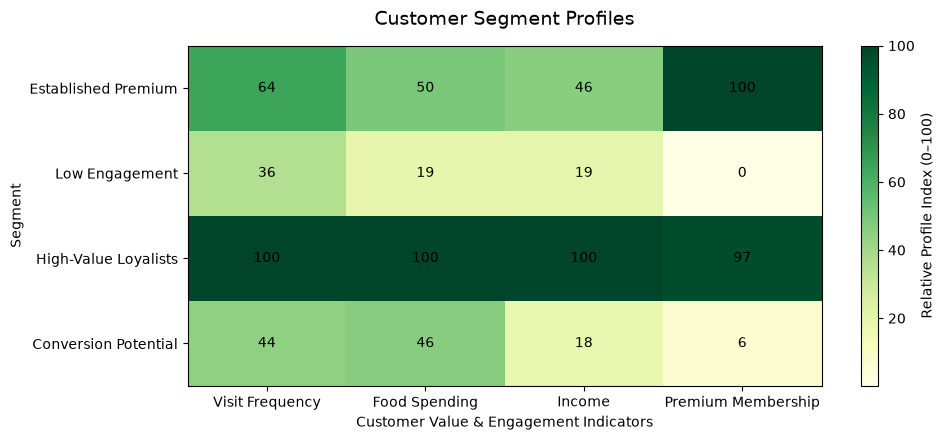

In [40]:
fig, ax = plt.subplots(figsize=(10, 4.5))

im = ax.imshow(
    profile_normalized,
    aspect="auto",
    cmap="YlGn"
)

ax.set_xticks(range(len(profile_normalized.columns)))
ax.set_xticklabels([
    "Visit Frequency",
    "Food Spending",
    "Income",
    "Premium Membership"
])

ax.set_yticks(range(len(profile_normalized.index)))
ax.set_yticklabels(profile_normalized.index)

for i in range(len(profile_normalized.index)):
    for j in range(len(profile_normalized.columns)):
        value = profile_normalized.iloc[i, j]

        ax.text(
            j,
            i,
            f"{value:.0f}",
            ha="center",
            va="center",
            fontsize=10
        )

ax.set_title("Customer Segment Profiles", fontsize=14, pad=15)
ax.set_xlabel("Customer Value & Engagement Indicators")
ax.set_ylabel("Segment")

cbar = plt.colorbar(im, ax=ax)
cbar.set_label("Relative Profile Index (0–100)")

plt.tight_layout()
plt.show()

In [41]:
print("Rows:", len(df_segmented))
print("Unique customers:", df_segmented["id_persona"].nunique())
print("Missing segment labels:", df_segmented["segment"].isna().sum())

print("\nSegment distribution:")
print(
    df_segmented["segment"]
    .value_counts()
)

Rows: 30000
Unique customers: 30000
Missing segment labels: 0

Segment distribution:
segment
Low Engagement          10077
Established Premium      7945
Conversion Potential     7136
High-Value Loyalists     4842
Name: count, dtype: int64


In [42]:
output_path = Path("../data/processed/customers_segmented.csv")

df_segmented.to_csv(
    output_path,
    index=False
)

print(f"Segmented dataset saved to: {output_path}")
print(f"Shape: {df_segmented.shape}")

Segmented dataset saved to: ..\data\processed\customers_segmented.csv
Shape: (30000, 18)


In [43]:
df_check = pd.read_csv(output_path)

print("Saved shape:", df_check.shape)
print("Unique customers:", df_check["id_persona"].nunique())
print("Missing segments:", df_check["segment"].isna().sum())
print("Segments:", df_check["segment"].unique())

Saved shape: (30000, 18)
Unique customers: 30000
Missing segments: 0
Segments: <ArrowStringArray>
[ 'Established Premium', 'Conversion Potential',       'Low Engagement',
 'High-Value Loyalists']
Length: 4, dtype: str


## Comparison with the Original Rule-Based Segmentation

The original version of this project proposed four customer segments using
predefined business rules:

- Premium Active
- Frequent Conscious
- Medium Exploratory
- Occasional Low-Spend

While this approach provided an initial business framework, the number and
definition of the segments were established before statistically evaluating
the underlying customer structure.

In this updated analysis, the segmentation was rebuilt using an unsupervised
machine learning approach.

K-Means solutions from K=2 to K=8 were evaluated using:

- Silhouette score
- Inertia
- Cluster size
- Behavioral differentiation
- Business interpretability

K=2 produced the strongest statistical separation, but resulted in a broad
high-value vs. lower-value division with limited commercial actionability.

K=6 and K=8 introduced additional complexity, including clusters increasingly
separated by age rather than meaningful differences in customer behavior.

K=4 provided the best balance between statistical validity, interpretability,
segment size, and commercial usefulness.

Importantly, the final number of four segments was not selected because the
original project also contained four groups. It emerged independently from
the model evaluation process.

The resulting data-driven segments are:

1. **Established Premium**
2. **Low Engagement**
3. **High-Value Loyalists**
4. **Conversion Potential**

The updated approach therefore moves the project from predefined customer
categories toward an evidence-based Customer Intelligence framework where
segments are discovered from actual patterns in customer behavior and value.

## Conclusion

This analysis identified four distinct customer segments across a dataset of
30,000 restaurant customers.

The strongest differences between segments were associated with customer
value and engagement variables, particularly visit frequency, food spending,
income, and Premium membership.

Demographic and preference variables such as age, food preference, and payment
method showed comparatively limited differentiation between segments.

Geography, however, revealed meaningful market differences. Miami showed
strong affinity with high-value customer profiles, Chicago was strongly
associated with the Low Engagement segment, and NYC showed particularly high
affinity with Conversion Potential customers.

These findings demonstrate that customer segmentation can support different
commercial strategies across both customer profiles and geographic markets.

The resulting segmentation provides a foundation for:

- targeted retention campaigns,
- Premium membership conversion,
- customer reactivation,
- VIP and loyalty strategies,
- market-specific commercial actions,
- and future customer lifetime value analysis.

The segmented customer dataset generated in this notebook will be used as the
foundation for the next stages of the Customer Intelligence project.